# 2 · Grad-CAM and Grad-CAM++ analysis

What does the frozen encoder look at when it places an image in its cluster?

The encoder has no classifier, so the explanation target is label-free: the cosine similarity between an image's
(mean-centred) feature and the centroid of the cluster it was assigned to by k-means on the held-out features.
Bounding boxes are used **only to score** the heatmaps.

- **Live here:** heatmaps for example images and localisation scores on a 60-image subset, from the released weights.
- **Stored (`results/gradcam/`):** the full 360-image analysis for both models. Set `FULL = True` to recompute it
  (about 2 minutes per model on a mid-range GPU, much longer on a small one).

In [1]:
import json, os, sys, warnings
from pathlib import Path
import numpy as np, pandas as pd, torch, matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)                                   # all paths below are relative to the repository root
from defect_aware_mae import data, evaluate, hub, report
from defect_aware_mae.data import CLASSES, load_split
from defect_aware_mae.models import embed, load_encoder
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
pd.set_option("display.max_colwidth", 90); pd.set_option("display.width", 220)
print("repo:", ROOT.name, "| device:", DEVICE, "| torch", torch.__version__)
from defect_aware_mae.gradcam import Explainer, run as gradcam_run
FULL = False

repo: defect-aware-MAE | device: cuda | torch 2.4.0+cu121


In [2]:
E = {}
for name, title in (("defect_aware_mae", "Defect-aware MAE"), ("simclr", "SimCLR")):
    path, mode = hub.download(name)
    E[title] = Explainer(path, mode, DEVICE)
    print(title, "| readout", mode, "| cluster sizes", np.bincount(E[title].lab).tolist())

Defect-aware MAE | readout mid | cluster sizes [50, 70, 56, 64, 60, 60]


SimCLR | readout cls | cluster sizes [62, 60, 55, 69, 54, 60]


## Heatmaps for one image per class

Green boxes are the ground-truth defect annotations (never used in training).

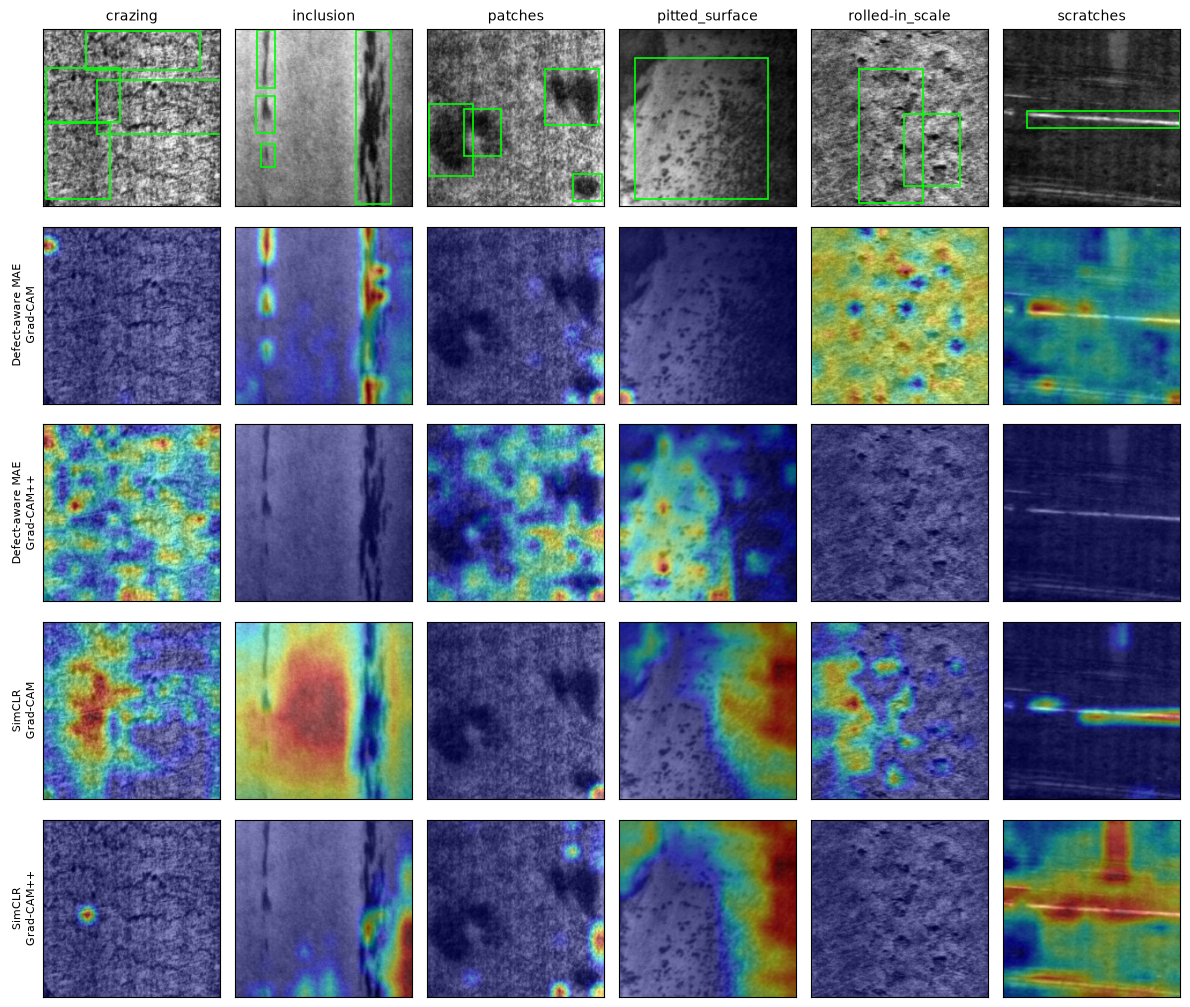

In [3]:
X, y, B = load_split("validation"); rng = np.random.RandomState(3)
idx = np.array([int(rng.choice(np.where(y == c)[0])) for c in range(6)])
rows = [(t, m) for t in E for m in ("gradcam", "gradcampp")]
fig, ax = plt.subplots(1 + len(rows), 6, figsize=(12, 2.05 * (1 + len(rows))))
for c, i in enumerate(idx):
    ax[0, c].imshow(X[i], cmap="gray"); ax[0, c].set_title(CLASSES[c], fontsize=10)
    for x0, y0, x1, y1 in B[i]:
        ax[0, c].add_patch(plt.Rectangle((x0*224, y0*224), (x1-x0)*224, (y1-y0)*224, fill=False, ec="lime", lw=1.2))
for r, (t, m) in enumerate(rows):
    C = E[t].cams(idx, m)
    for c, i in enumerate(idx):
        ax[r+1, c].imshow(X[i], cmap="gray"); ax[r+1, c].imshow(C[c], cmap="jet", alpha=.45, vmin=0, vmax=1)
    ax[r+1, 0].set_ylabel(f"{t}\n{'Grad-CAM' if m == 'gradcam' else 'Grad-CAM++'}", fontsize=8)
for a in ax.ravel(): a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.savefig("figures/gradcam_examples.png", dpi=160); plt.show()

## Live localisation scores on a 60-image subset (10 per class)

`EiB_lift` = heatmap energy inside the boxes divided by the box area (1.0 = a uniform map). `PG` = fraction of
images whose heatmap maximum falls inside a box.

In [4]:
sub = np.concatenate([np.random.RandomState(0).choice(np.where(y == c)[0], 10, replace=False) for c in range(6)])
rows = []
for t in E:
    for m in ("gradcam", "gradcampp"):
        rows.append({"Model": t, "Method": m, **{k: round(v, 3) for k, v in E[t].localization(E[t].cams(sub, m), sub).items()}})
pd.DataFrame(rows)

,Model,Method,EiB,area,EiB_lift,PG
0,Defect-aware MAE,gradcam,0.374,0.418,1.421,0.350
1,Defect-aware MAE,gradcampp,0.417,0.418,1.341,0.400
2,SimCLR,gradcam,0.446,0.418,1.270,0.383
3,SimCLR,gradcampp,0.272,0.418,0.676,0.283


In [5]:
if FULL:   # recompute the stored analysis for the two released checkpoints
    for name, out in (("defect_aware_mae", "defect_aware_mae"), ("simclr", "simclr")):
        path, mode = hub.download(name); gradcam_run(path, out, mode, device=DEVICE)

## Stored full analysis (360 images)

Deletion / insertion: area under the target-score curve when the highest-ranked 16×16 patches are blurred out /
revealed first; the random-order value is the reference.

In [6]:
names = {"simclr": "SimCLR", "defect_aware_mae": "Defect-aware MAE"}
GC = {k: json.load(open(f"results/gradcam/gradcam_{k}.json")) for k in names}
rows = []
for k, t in names.items():
    for m in ("gradcam", "gradcampp"):
        r, f = GC[k][m], GC[k][m]["faithfulness"]
        rows.append({"Model": t, "Readout": GC[k].get("mode", "cls"), "Method": "Grad-CAM" if m == "gradcam" else "Grad-CAM++",
                     "EiB": round(r["EiB"], 3), "EiB lift": round(r["EiB_lift"], 2), "Pointing game": round(r["PG"], 2),
                     "Deletion": round(f["del"], 3), "Deletion (random)": round(f["del_rand"], 3),
                     "Insertion": round(f["ins"], 3), "Insertion (random)": round(f["ins_rand"], 3)})
pd.DataFrame(rows)

,Model,Readout,Method,EiB,EiB lift,Pointing game,Deletion,Deletion (random),Insertion,Insertion (random)
0,SimCLR,cls,Grad-CAM,0.436,1.25,0.42,0.367,0.394,0.332,0.388
1,SimCLR,cls,Grad-CAM++,0.275,0.67,0.29,0.345,0.394,0.370,0.388
2,Defect-aware MAE,mid,Grad-CAM,0.405,1.15,0.43,0.640,0.664,0.660,0.660
3,Defect-aware MAE,mid,Grad-CAM++,0.394,0.98,0.38,0.642,0.664,0.650,0.660


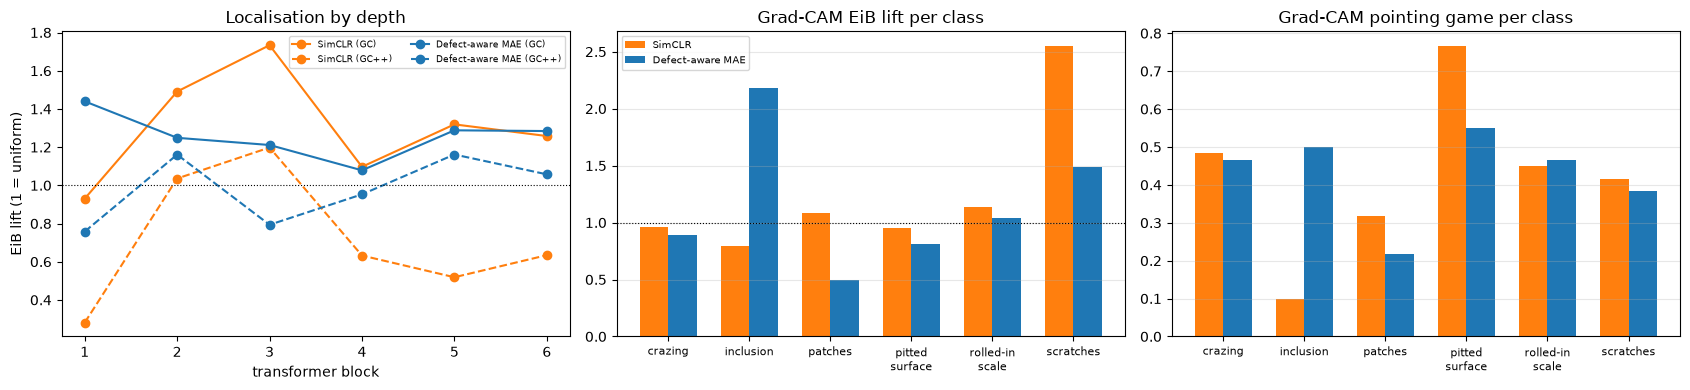

In [7]:
col = dict(zip(names, ["tab:orange", "tab:blue"])); fig, ax = plt.subplots(1, 3, figsize=(17, 4)); w = 0.35
for j, (k, t) in enumerate(names.items()):
    for m, ls in (("gradcam", "-"), ("gradcampp", "--")):
        L = GC[k][m]["layerwise"]; ax[0].plot(range(1, 7), [L[str(l)]["EiB_lift"] for l in range(6)], ls, marker="o", c=col[k], label=f"{t} ({'GC' if m == 'gradcam' else 'GC++'})")
    pc = GC[k]["gradcam"]["per_class"]
    ax[1].bar(np.arange(6) + (j - 0.5) * w, [pc[c]["EiB_lift"] for c in CLASSES], w, color=col[k], label=t)
    ax[2].bar(np.arange(6) + (j - 0.5) * w, [pc[c]["PG"] for c in CLASSES], w, color=col[k])
ax[0].axhline(1, c="k", lw=.8, ls=":"); ax[0].set_xlabel("transformer block"); ax[0].set_ylabel("EiB lift (1 = uniform)"); ax[0].set_title("Localisation by depth"); ax[0].legend(fontsize=6.5, ncol=2)
for a, t in ((ax[1], "Grad-CAM EiB lift per class"), (ax[2], "Grad-CAM pointing game per class")):
    a.set_xticks(range(6)); a.set_xticklabels([c.replace("_", "\n") for c in CLASSES], fontsize=8); a.set_title(t); a.grid(alpha=.3, axis="y")
ax[1].axhline(1, c="k", lw=.8, ls=":"); ax[1].legend(fontsize=7); plt.tight_layout(); plt.savefig("figures/gradcam_quantitative.png", dpi=160); plt.show()